# Figure 2 · Sample properties

Training, validation, and test distributions over a light-gray parent histogram.
The parent is COSMOS2020 galaxy-class objects within the geometric overlap of
the NISP and JWST mosaics used for extraction, before sample magnitude,
redshift, size, pixel-quality, or spatial-buffer cuts. Mosaic rectangles include
masked pixels and internal gaps: the parent is not a detection-completeness sample.

**Run on the machine with the full COSMOS2020 FITS catalog.** Set `COSMOS_CATALOG`
below, or the `SUPERNISP_COSMOS_CATALOG` environment variable. Missing parent data
stops execution before plotting/exporting; the existing v03 manuscript figure stays intact.
Only catalog data and saved WCS headers are read. No models or image mosaics run.


In [1]:
from pathlib import Path
import sys
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v04'
from parent_sample import load_parent, valid_values, probability_density

In [2]:
# Review controls: figure size, histogram bins, colors, export version.
FIGSIZE = (7.2, 2.8)
# Edit this path on your catalog/mosaic machine, if it is not at the default.
COSMOS_CATALOG = Path(os.environ.get('SUPERNISP_COSMOS_CATALOG',
    str(ROOT / 'catalog/COSMOS2020_CLASSIC_R1_v2.2_p3.fits'))).expanduser()
PARENT_COLOR = '#BDBDBD'
# Explicit missing-value codes; verify these if using a different catalog release.
CATALOG_SENTINELS = (-99, 99, -999, 999)
# Show the population beyond the sample cuts. Tails outside these axes retain
# their probability: do not renormalize the parent to only the displayed interval.
MAG_BINS = np.linspace(16, 30, 43)
REDSHIFT_BINS = np.linspace(0, 6, 51)
UPDATE_PAPER = True  # After successful export, install the PDF and update its caption.
PROPERTY_SPLITS = ['train', 'validation', 'test']
PROPERTY_COLORS = dict(train='#009E73', validation='#E69F00', test='#8856A7')
manifest_path = DATA / 'manifest.json'
objects_path = DATA / 'objects.csv'
manifest = read_json(manifest_path)
objects = pd.read_csv(objects_path)
assert len(objects) == manifest['accepted']
assert objects.id_classic.is_unique and objects.row.is_unique
assert objects.groupby('split').size().to_dict() == manifest['split_counts']
assert manifest['accepted'] + sum(manifest['rejection_counts'].values()) == manifest['candidates']
display(pd.DataFrame({'split': list(manifest['split_counts']),
                      'galaxies': list(manifest['split_counts'].values())}))
print('Selection:', manifest['selection'])
print('Quality:', manifest['quality'])

Selection: lp_type==0; ACS_F814W_MAG<25; .01<ez_z_phot<3; 4<FLUX_RADIUS<500; existing dated coverage candidates
Quality: DQ==0; finite SCI and positive finite RMS<1e7; >=95% coverage each instrument; central 5x5 NISP /25x25 HR fully valid


,split,galaxies
0,train,17816
1,test,2876
2,validation,2118


In [3]:
parent, parent_metadata, header_paths = load_parent(COSMOS_CATALOG, DATA)
assert set(objects.id_classic).issubset(set(parent.id_classic)), (
    'Some selected IDs are absent from the parent. Check catalog release and footprint headers.')
display(pd.DataFrame([parent_metadata]))
print('Gray parent: galaxy classification and geometric footprint only; no sample science cuts.')


Gray parent: galaxy classification and geometric footprint only; no sample science cuts.


Set DATE-AVG to '2023-05-19T02:22:00.480' from MJD-AVG.
Set DATE-END to '2024-04-17T18:10:49.417' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to     8.960368 from OBSGEO-[XYZ].
Set OBSGEO-H to 1686657736.922 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set DATE-AVG to '2023-04-10T11:22:19.996' from MJD-AVG.
Set DATE-END to '2023-04-12T05:00:46.307' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to     0.069751 from OBSGEO-[XYZ].
Set OBSGEO-H to 1275298804.365 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set DATE-AVG to '2023-09-27T11:03:01.111' from MJD-AVG.
Set DATE-END to '2024-04-23T13:15:45.700' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to   -10.186092 from OBSGEO-[XYZ].
Set OBSGEO-H to 1379678684.759 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set DATE-AVG to '2023-12-26T22:27:58.236' from MJD-AVG.
Set DATE-END to '2024-04-17T18:10:49.417' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to     8.993178 from OBSGEO-[XYZ].
Set OBSGEO-H to 1696581191.179 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set DATE

,catalog_rows,galaxy_class_rows,parent_rows,selection,footprint,source_mosaics
0,1720700,1677646,269169,lp_type == 0; within union(NISP pixel rectangl...,Geometric WCS coverage from sample source head...,"{'nisp': 4, 'jwst': 19}"


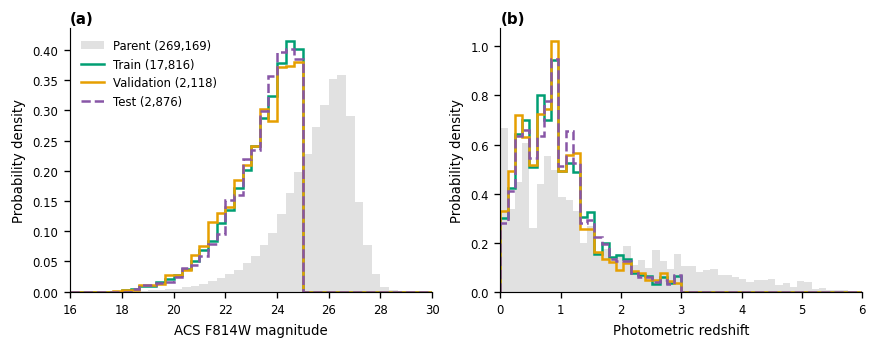

objects  ...  outside_display
ACS_F814W_MAG parent       269169  ...               21
              train         17816  ...                0
              validation     2118  ...                0
              test           2876  ...                0
ez_z_phot     parent       269169  ...             4961
              train         17816  ...                0
              validation     2118  ...                0
              test           2876  ...                0

[8 rows x 4 columns]

In [4]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, layout="constrained")
mag_bins, z_bins = MAG_BINS, REDSHIFT_BINS
histogram_accounting = {}
for ax, column, bins, xlabel, letter in [
    (axes[0], 'ACS_F814W_MAG', mag_bins, 'ACS F814W magnitude', 'a'),
    (axes[1], 'ez_z_phot', z_bins, 'Photometric redshift', 'b')]:
    histogram_accounting[column] = {}
    populations = [('parent', parent)] + [
        (split, objects.loc[objects.split == split]) for split in PROPERTY_SPLITS]
    for name, frame in populations:
        values = valid_values(frame, column, CATALOG_SENTINELS)
        density = probability_density(values, bins)
        shown = np.histogram(values, bins=bins)[0].sum()
        histogram_accounting[column][name] = dict(
            objects=len(frame), valid_measurements=len(values),
            invalid_measurements=len(frame)-len(values),
            outside_display=int(len(values)-shown))
        if name == 'parent':
            ax.stairs(density, bins, fill=True, color=PARENT_COLOR, alpha=.45,
                      linewidth=0, label=f'Parent ({len(frame):,})', zorder=0)
        else:
            ax.stairs(density, bins, linewidth=1.5, color=PROPERTY_COLORS[name],
                      linestyle='--' if name == 'test' else '-',
                      label=f'{name.capitalize()} ({len(frame):,})', zorder=2)
    ax.set(xlabel=xlabel, ylabel='Probability density', xlim=(bins[0], bins[-1]))
    ax.text(0, 1.02, f'({letter})', transform=ax.transAxes, fontsize=9, fontweight='bold')
axes[0].legend(frameon=False, loc='upper left')
plt.show()
display(pd.DataFrame({(column, name): counts
    for column, populations in histogram_accounting.items()
    for name, counts in populations.items()}).T)


In [5]:
# Full-catalog hashing is streamed to avoid loading the multi-GB FITS into RAM.
from sample_region import digest
parent_metadata['catalog_path'] = str(COSMOS_CATALOG.resolve())
parent_metadata['catalog_sha256'] = digest(COSMOS_CATALOG)
parent_metadata['histogram_accounting'] = histogram_accounting
parent_record = FIGURES / 'inputs' / f'parent_sample_{VERSION}.json'
parent_record.write_text(json.dumps(parent_metadata, indent=2) + '\n')
paths = export(fig, f'fig02_sample_properties_{VERSION}', '02_sample_properties.ipynb',
    [manifest_path, objects_path, parent_record, FIGURES / 'parent_sample.py', *header_paths],
    dict(figsize=FIGSIZE, property_splits=PROPERTY_SPLITS,
         colors=PROPERTY_COLORS, parent_color=PARENT_COLOR, legend='left panel only',
         magnitude_bins=mag_bins.tolist(), redshift_bins=z_bins.tolist(),
         catalog_sentinels=CATALOG_SENTINELS,
         normalization='Per sample and quantity: all valid measurements, including tails outside axes',
         parent=parent_metadata,
         test_access='catalog magnitude/redshift only; no images, predictions or performance metrics'),
    status='Figure 2: selected splits and geometric-footprint parent catalog')

if UPDATE_PAPER:
    import shutil
    import re
    manuscript = ROOT / 'paper/survey_enhancements.tex'
    text = manuscript.read_text()
    pattern = r'\\begin\{figure\*\}(?:(?!\\end\{figure\*\}).)*?\\label\{fig:sample_properties\}\s*\\end\{figure\*\}'
    matches = list(re.finditer(pattern, text, flags=re.S))
    if len(matches) != 1:
        raise ValueError('Expected exactly one sample-properties figure in the manuscript.')
    caption = r"""ACS F814W magnitude (a) and photometric-redshift (b) distributions of the training (teal), validation (orange), and test (dashed purple) samples.
    Gray shading shows COSMOS2020 galaxies within the overlapping mosaic footprints before the sample cuts.
    Histograms use common bins and are normalized by all valid measurements in each sample, including those outside the displayed ranges."""
    block = ('\\begin{figure*}[t]\n    \\centering\n'
             f'    \\includegraphics[width=\\textwidth]{{figs/sample_properties_{VERSION}.pdf}}\n'
             '    \\caption{' + caption + '}\n'
             '    \\label{fig:sample_properties}\n\\end{figure*}')
    target = ROOT / 'paper/figs' / f'sample_properties_{VERSION}.pdf'
    shutil.copy2(next(path for path in paths if path.suffix == '.pdf'), target)
    match = matches[0]
    manuscript.write_text(text[:match.start()] + block + text[match.end():])
    print('Updated manuscript Figure 2:', target)


Exported: fig02_sample_properties_v04.pdf, fig02_sample_properties_v04.svg, fig02_sample_properties_v04.png
Updated manuscript Figure 2: /Users/shemmati/Dropbox/superNISP/paper/figs/sample_properties_v04.pdf


## Working caption

Optical-magnitude (a) and photometric-redshift (b) distributions of the matched
training (17,816), validation (2,118) and reserved-test (2,876) samples. Gray shading shows the parent galaxy population within the geometric mosaic
overlap before the sample cuts. Histograms use common bins and are normalized
by all valid measurements per quantity and population, including tails outside
the displayed ranges. Legend counts are total objects; invalid measurements
and out-of-range counts are reported in the table above.
Training is teal, validation orange, and test dashed purple. The ACS F814W magnitude cut is 25, and
the selected photometric-redshift range is 0.01–3. The sample is optically
selected, not a NISP-complete galaxy sample.

## How the splits are used

- **Training:** optimizer updates and fitting the fixed normalization scales.
- **Validation:** development, checkpoint selection, architecture comparisons,
  and refinement of the observed-shape measurement protocol. Residual runs
  select checkpoints by masked MAE on all 2,118 validation objects; diffusion
  uses generated physical MAE on a fixed 256-object monitor, followed by the
  full 2,118-object validation analysis. Current shape comparisons are therefore
  development results, not final held-out performance estimates.
- **Test:** reserved for final reconstruction and observed-shape evaluation
  after the models, checkpoints, measurement settings, masks and reporting
  choices are frozen. Do not retune those choices based on test results.

Splits use disjoint 3-arcmin sky blocks, with 10-arcsec boundary buffers rather
than an independent random split of neighboring galaxies. This reduces local
spatial leakage, but all splits are in COSMOS and do not establish generalization
to another field. This figure reads test catalog properties only; no test images
or model outputs are accessed. These histograms describe the fixed split and
must not be used to reshuffle it or tune the models to the test distribution.
